#Enfermedades de plantas

https://www.tensorflow.org/datasets/catalog/plant_leaves?hl=es-419

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import tensorflow_datasets as tfds

In [ ]:
pip install tensorflow-datasets

In [ ]:
# Cargar el dataset
%time dataset, info = tfds.load('plant_leaves', split='train', with_info=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_leaves/incomplete.PKHHN2_0.1.1/plant_leaves-train.tfrecord*...:   0%…

Dataset plant_leaves downloaded and prepared to /root/tensorflow_datasets/plant_leaves/0.1.1. Subsequent calls will reuse this data.
CPU times: user 1min 49s, sys: 27.4 s, total: 2min 16s
Wall time: 7min 46s


In [ ]:
len(dataset)

4502

In [ ]:
labels = []
for example in dataset:
  labels.append(example['label'].numpy())

In [ ]:
unique_elements, count_elements = np.unique(labels,return_counts=True)
print(unique_elements)
print(count_elements)


[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21]
[170 220 179 277 279 133 322 148 287 159 103 265 232 254 142 118 345 124
 276 272  77 120]


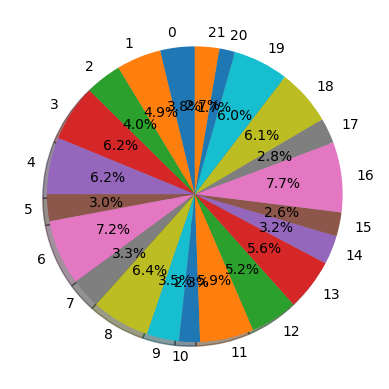

In [ ]:
fig1,ax1=plt.subplots()
ax1.pie( count_elements, labels=unique_elements, autopct='%1.1f%%',shadow=True,startangle=90 )
plt.show()

In [ ]:
# Iterar sobre el dataset
for example in dataset.take(5):
  image = example['image']
  label = example['label']
  print(image.shape, label.numpy())

(4000, 6000, 3) 2
(4000, 6000, 3) 7
(4000, 6000, 3) 1
(4000, 6000, 3) 18
(4000, 6000, 3) 6


In [ ]:
from tensorflow_datasets import visualization

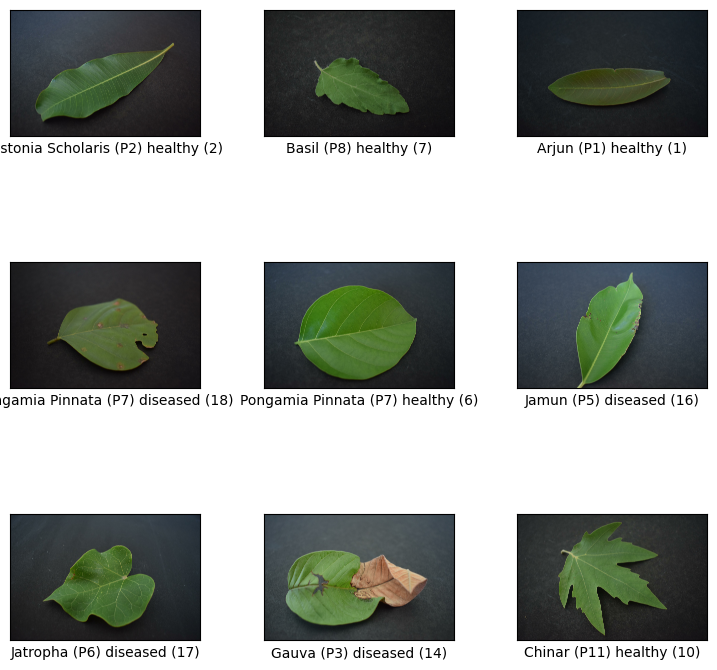

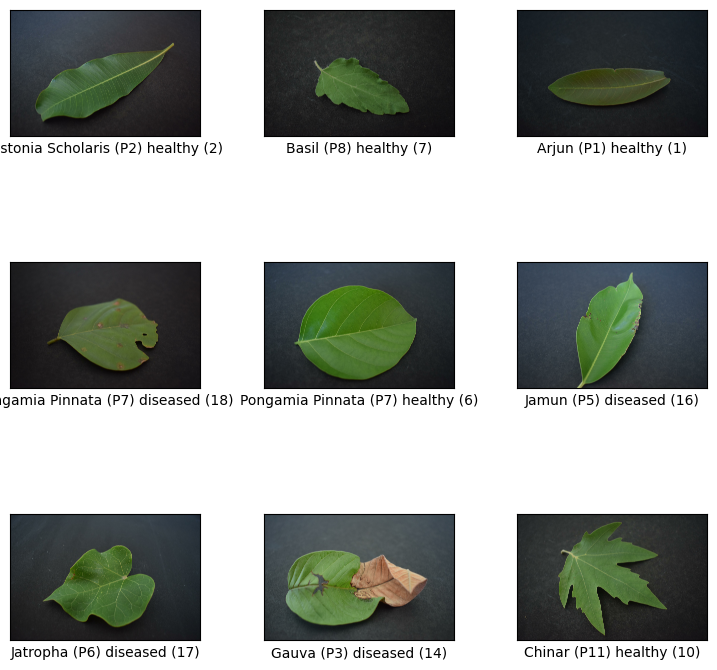

In [ ]:
# Visualizar las imágenes
visualization.show_examples(dataset, info)

## 1. Partición de datos y optimización del pipeline de entrada

In [ ]:
# Carga y partición del dataset en Train (80%), Val (10%) y Test (10%)
(train_raw, val_raw, test_raw), info = tfds.load(
    'plant_leaves',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    as_supervised=True,
    with_info=True
)

n_classes = info.features['label'].num_classes
print(f"Número de clases: {n_classes}")
print(f"Total imágenes en dataset: {info.splits['train'].num_examples}")

In [ ]:
# Redimensionamiento a 224x224 y pipeline con cache y prefetch
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def format_example(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_raw.map(format_example, num_parallel_calls=AUTOTUNE).cache().shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds = val_raw.map(format_example, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)
test_ds = test_raw.map(format_example, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

## 2. Aumento de datos (Data Augmentation) y Preprocesamiento

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Pipeline de aumento de datos
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# Función de preprocesamiento específica para MobileNetV2 (escala a [-1, 1])
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

## 3. Construcción del modelo con MobileNetV2 (Functional API)

In [ ]:
# Modelo base preentrenado en ImageNet-1K sin cabezal
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Congelar pesos en Fase 1
base_model.trainable = False

# Ensamblaje funcional protegiendo las estadísticas de BatchNormalization
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False) # Crítico: training=False mantiene BatchNorm en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(n_classes, activation='softmax', kernel_initializer='glorot_uniform')(x)

model = keras.Model(inputs, outputs)
model.summary()

## 4. Fase 1: Extracción de Características (Feature Extraction)

In [ ]:
# Compilación con tasa base y parada temprana
base_learning_rate = 1e-3
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=base_learning_rate),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

stop_early = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

epochs_fe = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs_fe,
    callbacks=[stop_early]
)

## 5. Fase 2: Ajuste Fino (Fine-Tuning)

In [ ]:
# Descongelar capas superiores del modelo base
base_model.trainable = True
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Capas entrenables en el modelo: {len(model.trainable_variables)}")

# Recompilar con tasa de aprendizaje reducida (100x menor)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

epochs_ft = 10
total_epochs = len(history.epoch) + epochs_ft

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=len(history.epoch),
    callbacks=[stop_early]
)

## 6. Curvas de aprendizaje

In [ ]:
# Visualización de curvas de exactitud y pérdida
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.plot([len(history.history['accuracy']) - 1, len(history.history['accuracy']) - 1],
         plt.ylim(), label='Inicio Fine-Tuning', linestyle='--')
plt.title('Exactitud')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.plot([len(history.history['loss']) - 1, len(history.history['loss']) - 1],
         plt.ylim(), label='Inicio Fine-Tuning', linestyle='--')
plt.title('Pérdida')
plt.legend(loc='upper right')
plt.show()

## 7. Evaluación en conjunto de prueba y matriz de confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Evaluación cuantitativa en test
test_loss, test_acc = model.evaluate(test_ds)
print(f"Pérdida en Test: {test_loss:.4f}")
print(f"Exactitud en Test: {test_acc:.4f}")

# Predicciones y matriz de confusión
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)

cm = confusion_matrix(y_true, y_pred)
print(cm)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión - Plant Leaves (22 clases)')
plt.show()

## 8. Guardado del modelo entrenado

In [ ]:
# Guardado en formato Keras nativo y H5
model.save('modelo_plant_leaves.keras')
model.save('modelo_plant_leaves.h5')
print("Modelo exportado exitosamente como 'modelo_plant_leaves.keras' y 'modelo_plant_leaves.h5'.")